In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 설정: Windows
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지

# 한스 로슬링

## 데이터 불러오기
 - 많은 라이브러리에는 샘플 데이터가 있다.
 - plotly에는 gapminder 데이터가 내장되어 있으며 이를 불러와 사용할 수 있다.

In [2]:
df = px.data.gapminder()
df
# 출산률 데이터가 없다.

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4
...,...,...,...,...,...,...,...,...
1699,Zimbabwe,Africa,1987,62.351,9216418,706.157306,ZWE,716
1700,Zimbabwe,Africa,1992,60.377,10704340,693.420786,ZWE,716
1701,Zimbabwe,Africa,1997,46.809,11404948,792.449960,ZWE,716
1702,Zimbabwe,Africa,2002,39.989,11926563,672.038623,ZWE,716


In [3]:
# 출산률 데이터가 없으므로 찾아서 가져온다.
## 출처 https://ourworldindata.org/fertility-rate
df2 = pd.read_csv('./data/fertility.csv')
df2

,Entity,Code,Year,Total fertility rate
0,Afghanistan,AFG,1950,7.248
1,Afghanistan,AFG,1951,7.260
2,Afghanistan,AFG,1952,7.260
3,Afghanistan,AFG,1953,7.266
4,Afghanistan,AFG,1954,7.254
...,...,...,...,...
19397,Zimbabwe,ZWE,2019,3.748
19398,Zimbabwe,ZWE,2020,3.754
19399,Zimbabwe,ZWE,2021,3.765
19400,Zimbabwe,ZWE,2022,3.767


In [4]:
# 두 데이터를 하나로 조인한다.
# Code, year를 기준으로 조인이 가능하다.
df_f = df.merge(df2, how='left', left_on = ['iso_alpha', 'year'], right_on = ['Code', 'Year'])

# 머신러닝 코드 맛보기
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler(feature_range=(5,50))
df_f['pop_size'] = mm.fit_transform(df_f[['pop']])

df_f

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num,Entity,Code,Year,Total fertility rate,pop_size
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4,Afghanistan,AFG,1952,7.260,5.285479
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4,Afghanistan,AFG,1957,7.264,5.313313
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4,Afghanistan,AFG,1962,7.292,5.348332
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4,Afghanistan,AFG,1967,7.339,5.391703
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4,Afghanistan,AFG,1972,7.453,5.444308
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1699,Zimbabwe,Africa,1987,62.351,9216418,706.157306,ZWE,716,Zimbabwe,ZWE,1987,5.500,5.312476
1700,Zimbabwe,Africa,1992,60.377,10704340,693.420786,ZWE,716,Zimbabwe,ZWE,1992,4.567,5.363254
1701,Zimbabwe,Africa,1997,46.809,11404948,792.449960,ZWE,716,Zimbabwe,ZWE,1997,4.075,5.387163
1702,Zimbabwe,Africa,2002,39.989,11926563,672.038623,ZWE,716,Zimbabwe,ZWE,2002,3.925,5.404964


In [5]:
fig = px.scatter(data_frame=df_f,
    x='Total fertility rate',
    y='lifeExp',
    color='continent',
    size='pop_size',
    hover_name='country',
    hover_data=['Code', 'iso_num'],
    animation_group='country',
    animation_frame='Year',
    title="The best stats you've ever seen",
    width=1100,
    height=800,)
fig.update_xaxes(range=[0.5, 9])
fig.update_yaxes(range=[25, 90])


# 원주시 맛집지도

In [6]:
# 데이터 불러오기
df1 = pd.read_csv('./data/식당기본정보.csv', encoding='utf-8-sig')
df2 = pd.read_csv('./data/식당운영정보.csv', encoding='cp949')
df3 = pd.read_csv('./data/식당품질정보.csv', encoding='utf-8-sig')

dfs = [df1, df2, df3]

In [7]:
# 여러 df를 한번에 보여주는 함수
def dp_df(dfs, method, *args, **kargs):
    for df in dfs:
        display(getattr(df, method)(*args, **kargs))

dp_df(dfs, 'head', 5)

,식당(ID),식당명,도로명주소,지번주소,식당위도,식당경도,식당대표전화번호,영업신고증업태명,영업인허가명,음식점소개내용,식당상태
0,1656,유가호,강원도 원주시 원일로 209-1,강원도 원주시 학성동 290-12,37.355460,127.944246,033-742-3342,중국식,일반음식점,"강원도 원주시에서 가 볼 만한 식당을 찾으신다면? ""유가호""를 추천합니다! 지방자치...",운영중
1,3057,원주칼국수,강원도 원주시 중앙로 32,강원도 원주시 인동 25-11,37.346699,127.953713,033-764-0941,한식,일반음식점,"""원주칼국수""를 강원도 원주시의 가 볼 만한 식당으로 추천합니다! 다국어 메뉴판이 ...",운영중
2,3058,상훈 보쌈족발,강원도 원주시 무실로12번길 13,강원도 원주시 일산동 77-3,37.349171,127.948313,033-743-2625,한식,일반음식점,"어디 가야 할지 고민이시라고요? 그럼 강원도 원주시 맛집, ""상훈보쌈""을 추천합니다...",운영중
3,3427,연흥식당,강원도 원주시 평원로 1-1,강원도 원주시 중앙동 260,37.347290,127.953728,033-743-0589,한식,일반음식점,"어디 가야 할지 고민이시라고요? 그럼 강원도 원주시 맛집, ""연흥식당""을 추천합니다...",운영중
4,3428,민생회관,강원도 원주시 중앙로 46,강원도 원주시 중앙동 243-1,37.347398,127.953029,033-742-2837,한식,일반음식점,"강원도 원주시 근처로 갈 일정이 있으시다면, 맛집으로 소문난 ""민생회관""을 꼭 방문...",운영중


,식당(ID),식당명,지역명,입식좌석수,좌식좌석수,주차가능여부,와이파이제공여부,놀이방유무,반려동물입장가능여부,다국어메뉴판제공여부,...,홈페이지(URL),인근랜드마크명,인근랜드마크위도,인근랜드마크경도,인근랜드마크와거리,키오스크유무,모바일페이먼트유무,스마트오더유무,대표메뉴명,식당상태
0,1656,유가호,강원도 원주시,12,24,N,N,N,N,Y,...,NaN,구 조선식산은행 원주지점,37.34897,127.9514,187.799493,N,N,N,NaN,운영중
1,2200,본래순대 원주무실점,강원도 원주시,0,0,N,N,N,N,N,...,NaN,NaN,NaN,NaN,NaN,N,N,N,NaN,미확인
2,2497,치킨의민족 원주점,강원도 원주시,0,0,N,N,N,N,N,...,NaN,NaN,NaN,NaN,NaN,N,N,N,NaN,폐업
3,3057,원주칼국수,강원도 원주시,0,0,N,N,N,N,Y,...,NaN,구 조선식산은행 원주지점,37.34897,127.9514,150.868572,N,N,N,NaN,운영중
4,3058,상훈 보쌈족발,강원도 원주시,0,0,N,N,N,N,Y,...,NaN,구 조선식산은행 원주지점,37.34897,127.9514,142.588239,N,N,N,NaN,운영중


,식당(ID),식당명,지역명,어워드정보설명,(RTI)지수,온라인화진행여부,수용태세지수,인기도,트립어드바이저평점,씨트립평점,네이버평점,식당상태
0,3948,명랑막국수,강원도 원주시,NaN,0.18,Y,0.27,0.34,4.0,NaN,4.15,운영중
1,3949,산정집,강원도 원주시,안심식당,0.20,Y,0.18,0.60,4.5,NaN,4.33,운영중
2,4912,동승루,강원도 원주시,안심식당,0.14,Y,0.12,0.34,2.0,NaN,4.29,운영중
3,5420,영월장칼국수,강원도 원주시,NaN,0.18,Y,0.25,0.36,4.0,NaN,4.32,운영중
4,5423,무궁화집,강원도 원주시,안심식당,0.16,Y,0.25,0.10,3.0,NaN,4.17,운영중


In [8]:
dp_df(dfs, 'info')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3350 entries, 0 to 3349
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   식당(ID)    3350 non-null   int64  
 1   식당명       3350 non-null   object 
 2   도로명주소     3342 non-null   object 
 3   지번주소      3350 non-null   object 
 4   식당위도      3350 non-null   float64
 5   식당경도      3350 non-null   float64
 6   식당대표전화번호  2934 non-null   object 
 7   영업신고증업태명  2853 non-null   object 
 8   영업인허가명    2641 non-null   object 
 9   음식점소개내용   3350 non-null   object 
 10  식당상태      3350 non-null   object 
dtypes: float64(2), int64(1), object(8)
memory usage: 288.0+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3351 entries, 0 to 3350
Data columns (total 28 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   식당(ID)      3351 non-null   int64  
 1   식당명         3351 non-null   object 
 2   지역명         3347 non-null   object 
 3   입식좌석수       3351 non-null   int64  
 4   좌식좌석수       3351 non-null   int64  
 5   주차가능여부      3351 non-null   object 
 6   와이파이제공여부    3351 non-null   object 
 7   놀이방유무       3351 non-null   object 
 8   반려동물입장가능여부  3351 non-null   object 
 9   다국어메뉴판제공여부  3351 non-null   object 
 10  화장실정보내용     3351 non-null   object 
 11  휴무일정보내용     780 non-null    object 
 12  영업시간내용      1538 non-null   object 
 13  택배판매유무      3351 non-null   object 
 14  배리어프리유무     3351 non-null   object 
 15  배달서비스유무     3351 non-null   object 
 16  예약방식명       3351 non-null   object 
 17  온라인예약정보내용   872 non-null    object 
 18  홈페이지(URL)   715 non-null    object 
 19  인근랜드마크명     2005 non-null  

None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3351 entries, 0 to 3350
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   식당(ID)     3351 non-null   int64  
 1   식당명        3351 non-null   object 
 2   지역명        2642 non-null   object 
 3   어워드정보설명    330 non-null    object 
 4   (RTI)지수    2455 non-null   float64
 5   온라인화진행여부   3349 non-null   object 
 6   수용태세지수     3351 non-null   float64
 7   인기도        2278 non-null   float64
 8   트립어드바이저평점  82 non-null     float64
 9   씨트립평점      1 non-null      float64
 10  네이버평점      2671 non-null   float64
 11  식당상태       3351 non-null   object 
dtypes: float64(6), int64(1), object(5)
memory usage: 314.3+ KB


None

In [9]:
# id 갯수를 확인
len(set(df1['식당(ID)'])), len(set(df2['식당(ID)'])), len(set(df2['식당(ID)']))
# id 갯수는 하나 차이남
## 뭐가 차이나는거지?

(3350, 3351, 3351)

In [10]:
## id가 일치하는지 확인
### 자료형 중 set 기능을 활용 - list, dict같이 파이썬에서 기본 제공하는 자료형
for df_A in dfs:
    A = set(df_A['식당(ID)'])
    print(f'id 갯수{len(A)}')
    for df_B in dfs:
        B = set(df_B['식당(ID)'])
        print (f'ID {A - B}')
    print()

id 갯수3350
ID set()
ID set()
ID set()

id 갯수3351
ID {26698}
ID set()
ID set()

id 갯수3351
ID {26698}
ID set()
ID set()



In [11]:
df2[df2['식당(ID)'] == 26698]
# 26698id는
## df2,3에만 있음 많지는 않으므로 일단 다행

,식당(ID),식당명,지역명,입식좌석수,좌식좌석수,주차가능여부,와이파이제공여부,놀이방유무,반려동물입장가능여부,다국어메뉴판제공여부,...,홈페이지(URL),인근랜드마크명,인근랜드마크위도,인근랜드마크경도,인근랜드마크와거리,키오스크유무,모바일페이먼트유무,스마트오더유무,대표메뉴명,식당상태
100,26698,페리카나 평원점,강원도 원주시,0,0,N,N,N,N,Y,...,"https://www.pelicana.co.kr,http://www.instagra...",구 조선식산은행 원주지점,37.34897,127.9514,257.677038,N,N,N,NaN,운영중


## data merge

In [12]:
df = df1.merge(df2, how='left', on=['식당(ID)', '식당명', '식당상태']
       ).merge(df3, how='left', on=['식당(ID)', '식당명', '식당상태', '지역명'])

# 밀도기반 plot 시각화

<Axes: xlabel='식당경도', ylabel='식당위도'>

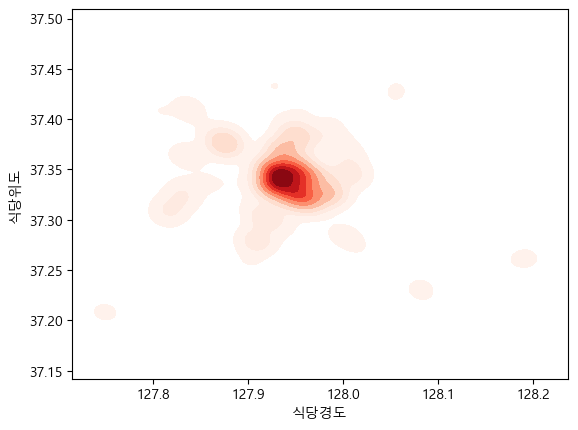

In [13]:
sns.kdeplot(data=df, x='식당경도', y='식당위도', 
            fill=True, cmap='Reds', levels=10)

# 지도에 시각화하기

In [14]:
# 지도 라이브러리를 이용
# folium이 없는 경우
# !pip install folium

import folium
from folium.plugins import HeatMap

lat_col = "식당위도"
lon_col = "식당경도"

map_df = df[[lat_col, lon_col]].dropna()

# 지도 중심
center = [map_df[lat_col].mean(), map_df[lon_col].mean() ]

# 지도 그리기
m = folium.Map(
    location=center,
    zoom_start=12 )

# 컬러맵
import branca.colormap as cm
colormap = cm.LinearColormap(
    colors=["red", "orange", "lightgreen"],
    vmin=df["네이버평점"].min(),
    vmax=df["네이버평점"].max(),
    caption="네이버 평점"
)

# 지도에 점 표시 CircleMaker
for row in df.itertuples():
    if pd.isna(row.네이버평점):
        color = "gray"
    else:
        color = colormap(row.네이버평점)
    # 위경도 jittering
    # print(row.식당위도)
    위도 = row.식당위도 + np.random.normal(0, 0.00010)
    경도 = row.식당경도 + np.random.normal(0, 0.00010)

    folium.CircleMarker(
        location=[위도, 경도],
        radius=row.네이버평점,
        fill=True,
        fill_color = color,
        fill_opacity=1,
        tooltip=f"{row.식당명} / {row.네이버평점}",
        stroke=True
    ).add_to(m)

HeatMap(
    data=map_df[[lat_col, lon_col]].values.tolist(),
    radius=15,
    blur=20,
    min_opacity=0.3
).add_to(m)

display(m)
m.save("restaurant_heatmap.html")
from IPython.display import FileLink
FileLink("restaurant_heatmap.html")

d:\jupyter\AIchemist\ML_lecture\2026_python_from_Basic_to_ML\2606_python_data\restaurant_heatmap.html

# 데이터 처리

In [15]:
df['동'] = df['지번주소'].str.split(expand=True)[2]

In [16]:
df.groupby('동').agg(
    갯수=('식당(ID)', 'count')
).sort_values(by='갯수', ascending=False).head(6).index

Index(['단계동', '무실동', '단구동', '지정면', '명륜동', '반곡동'], dtype='object', name='동')

# 동별 시각화

<Axes: xlabel='네이버평점', ylabel='Density'>

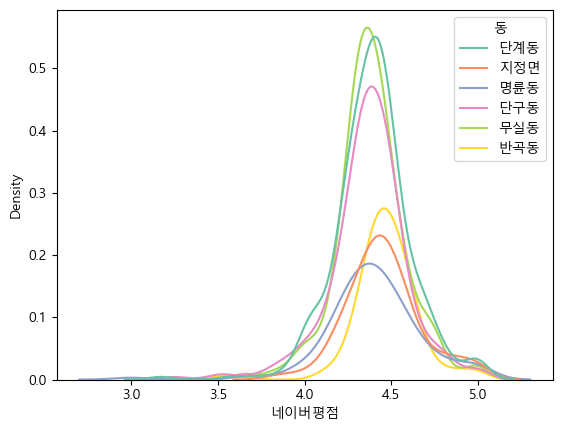

In [17]:
dongs = ['단계동', '무실동', '단구동', '지정면', '명륜동', '반곡동']
cond1 = df['동'].isin(dongs)
sns.kdeplot(data = df[cond1], x='네이버평점', hue='동', multiple='layer', palette='Set2')

In [18]:
df.groupby('동').agg(
    음식점수=('네이버평점', 'count'),
    평점평균=('네이버평점', 'mean'),
    평점중위=('네이버평점', 'median'),
    평점최대=('네이버평점', 'max'),
    평점최소=('네이버평점', 'min'),
).sort_values(by='평점평균', ascending=False).head(10)

,음식점수,평점평균,평점중위,평점최대,평점최소
동,,,,,
원동,20,4.516000,4.460,5.00,3.98
반곡동,140,4.469714,4.475,5.00,3.50
지정면,150,4.454667,4.435,5.00,3.83
일산동,62,4.450000,4.435,5.00,4.10
부론면,7,4.444286,4.500,4.79,3.79
명륜동,143,4.402098,4.390,5.00,3.00
개운동,94,4.399894,4.390,5.00,3.20
단계동,332,4.394127,4.400,5.00,3.17
흥업면,116,4.390862,4.370,5.00,3.30
